# Comparison with Cogwheel

`cogwheel` marginalizes the extrinsic parameters of a template by quasi-Monte Carlo importance sampling. We compare it with the likelihood ratio from the tables on the same segment and template in the setting of a background search, with no trigger so that the arrival time runs over the whole segment, with the template as its own relative-binning reference so that no reference waveform is searched for, and with one construction plus one call per segment and template.

`../scripts/run_cogwheel.py` runs `cogwheel` at finer and finer settings on four segments of `../data/segments/three_parameters.npz`, with mergers at SNR 1.4, 5.7, 8.5 and 12.7 (rows 0, 4, 6 and 8), and writes `../data/results/cogwheel_row<row>.npz` with the settings given in its docstring. The template of rows 6 and 8 is the injected binary, and for rows 0 and 4 it is the template stored in the result file, away from the injected binary. Here we compute the likelihood ratio from the tables for the same templates.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import numba
import matplotlib.pyplot as plt
import exmarg.search as search
from exmarg import figstyle

segments = '../data/segments/three_parameters.npz'
store = search.load_redshift_store('../tables/redshift', mmap=True)
cog = {row: np.load('../data/results/cogwheel_row%d.npz' % row) for row in (0, 4, 6, 8)}

## The Likelihood Ratio on One CPU Core

We compute the likelihood ratio of each template with the distance integrated over a prior uniform in volume, the prior of the `cogwheel` runs, and time it on one core as the `cogwheel` calls.

In [2]:
numba.set_num_threads(1)
ours, seconds = {}, {}
for row in (0, 4, 6, 8):
    bank = search.mass_bank(cog[row]['template'][None, :], segments, 'cpu')
    search.pe_intrinsic(segments, bank, store, rows=[row], prior='volume')          # compiles
    start = time.perf_counter()
    ours[row] = search.pe_intrinsic(segments, bank, store, rows=[row], prior='volume')['ln_lambda'][0, 0]
    seconds[row] = time.perf_counter() - start
    print('row %d: ln Lambda = %.4f in %.2f s on one core' % (row, ours[row], seconds[row]))

row 0: ln Lambda = -0.0081 in 0.70 s on one core


row 4: ln Lambda = 0.0659 in 0.69 s on one core


row 6: ln Lambda = 20.0347 in 0.87 s on one core


row 8: ln Lambda = 56.4535 in 0.86 s on one core


## The Normalization of the Arrival Time

`cogwheel` integrates the arrival time over seconds, so its $\ln\Lambda$ exceeds the value from the tables by $\ln 3.9$, the logarithm of the width of the window. For noise, halving the window lowers it by $\ln 2$, and a loud merger inside both windows keeps its value.

In [3]:
for row in (0, 4, 6, 8):
    lad, half = cog[row]['ladder'], cog[row]['half_window']
    print('row %d: halving the window moves ln Lambda by %.3f (ln 2 = %.3f)' % (row, half.mean() - lad[int(cog[row]['half_index']) if 'half_index' in cog[row] else 6, 2], np.log(2)))

row 0: halving the window moves ln Lambda by -0.693 (ln 2 = 0.693)
row 4: halving the window moves ln Lambda by -0.762 (ln 2 = 0.693)
row 6: halving the window moves ln Lambda by 0.014 (ln 2 = 0.693)
row 8: halving the window moves ln Lambda by -0.005 (ln 2 = 0.693)


## Accuracy against Cost

The figure shows the offset of `cogwheel` from the value of the tables after removing $\ln 3.9$, at every setting, against the cost of one segment and template, which is the construction plus one call. The error bars are the standard deviation over 20 calls, and over 5 calls for rows 6 and 8.

SNR 1.4: cogwheel offsets [-0.054 -0.065 -0.024 -0.021 -0.008 -0.015 -0.017 -0.017] at [15.8 15.8 16.  16.4 17.5 22.  22.6 49.7] s
SNR 5.7: cogwheel offsets [-0.109 -0.099 -0.046 -0.016 -0.01  -0.011 -0.013 -0.01 ] at [ 8.5  8.5  8.6  9.1 10.2 15.5 15.6 43.6] s
SNR 8.5: cogwheel offsets [0.15  0.15  0.15  0.144 0.157 0.151] at [5.7 5.7 5.7 5.7 5.7 5.7] s
SNR 12.7: cogwheel offsets [-0.055 -0.055 -0.055 -0.036 -0.037 -0.026] at [5.7 5.7 5.7 5.7 5.7 5.7] s


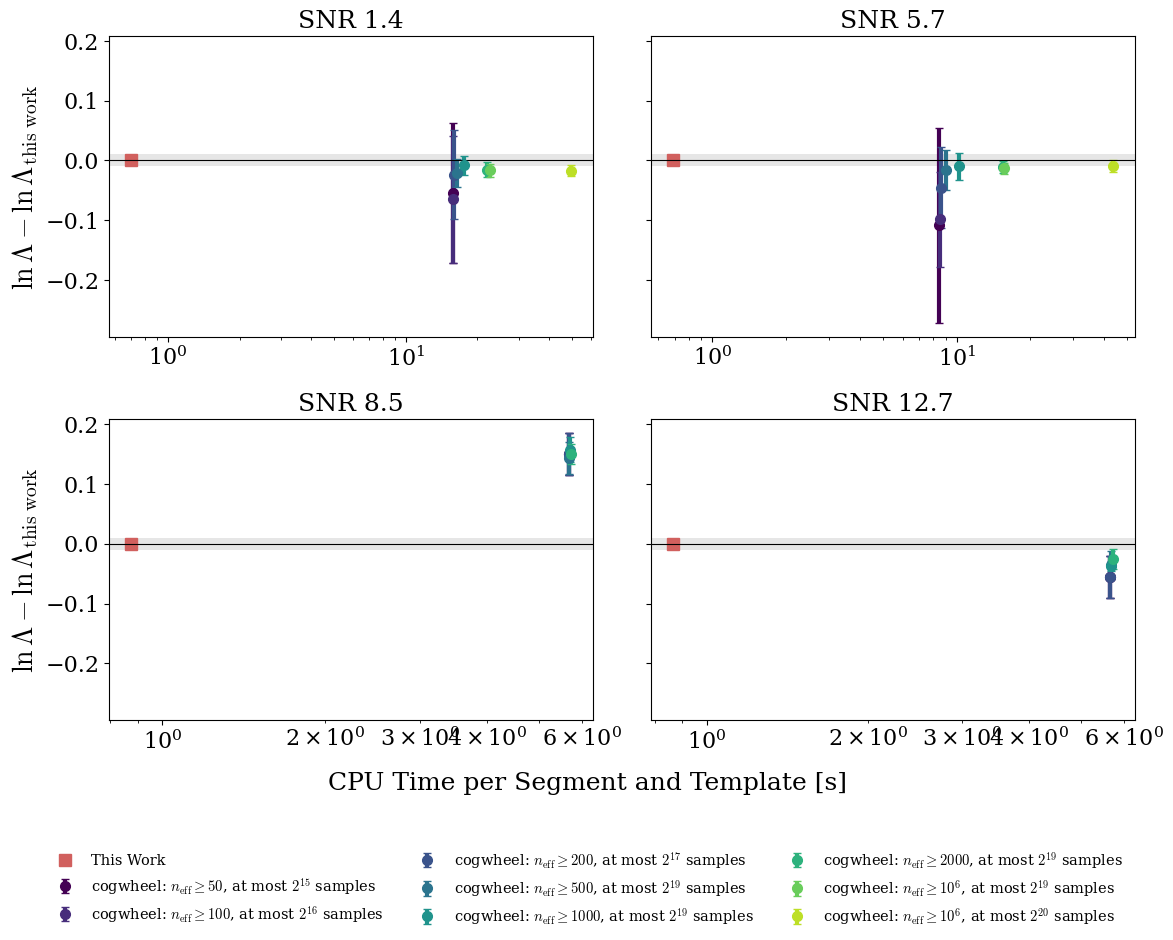

In [4]:
figstyle.apply()
fig, axs = plt.subplots(2, 2, figsize=(12, 9.5), sharey=True)
axs = axs.ravel()
for ax, row, title in zip(axs, (0, 4, 6, 8), ('SNR 1.4', 'SNR 5.7', 'SNR 8.5', 'SNR 12.7')):
    lad = cog[row]['ladder']
    offset = lad[:, 2] - np.log(float(cog[row]['t_range_width'])) - ours[row]
    cost = float(cog[row]['construction_s']) + lad[:, 4]
    ax.axhspan(-0.01, 0.01, color='0.9', lw=0)
    colors = plt.cm.viridis(np.linspace(0.0, 0.9, 8))         # one color per setting of the ladder
    for k in range(len(lad)):
        neff, cap = int(lad[k, 0]), int(lad[k, 1])
        label = r'cogwheel: $n_{\rm eff} \geq %s$, at most $2^{%d}$ samples' % ('10^6' if neff >= 10 ** 6 else str(neff), cap)
        ax.errorbar(cost[k], offset[k], yerr=lad[k, 3], fmt='o', color=colors[k], capsize=3, ms=7, label=label)
    ax.plot(seconds[row], 0.0, 's', color=figstyle.RED, ms=9, label='This Work')
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xscale('log'); ax.set_title(title)
    print('%s: cogwheel offsets %s at %s s' % (title, np.round(offset, 3), np.round(cost, 1)))
axs[0].set_ylabel(r'$\ln\Lambda - \ln\Lambda_{\rm this\ work}$')
axs[2].set_ylabel(r'$\ln\Lambda - \ln\Lambda_{\rm this\ work}$')
fig.tight_layout(rect=(0, 0.17, 1, 1))
fig.supxlabel('CPU Time per Segment and Template [s]', y=0.15)
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=10.5)
plt.show()

At its coarsest settings `cogwheel` scatters by about 0.1 in $\ln\Lambda$. With finer settings it settles within 0.02 of the value of the tables at SNR 1.4 and 5.7, and at SNR 8.5 and 12.7 it stays 0.15 above and 0.03 below it. We have not traced the origin of these two offsets.

## Posteriors

We compare posteriors on three segments with a merger, row 4 below threshold at SNR 5.7 and rows 6 and 8 at SNR 8.5 and 12.7. `cogwheel` samples the chirp mass, the mass ratio and the spin with `nautilus`, the extrinsic parameters marginalized, at the settings of the figure above (`../scripts/run_cogwheel_pe.py`, results in `../data/results/cogwheel_pe_row<row>_neff<n_eff>_cap<cap>.npz`). At SNR 5.7 and 8.5 the finer settings take several hours per run and are not shown. The posterior from the tables is computed on the grid of notebook 2 with 78,000 templates on the GPU. The prior of `cogwheel` is uniform in the two component masses, so we weight its samples by $(1+q)^2/M$ to give both posteriors the prior of the grid, uniform in total mass, mass ratio and spin, and keep its samples with $20 \le M^{\rm det} \le 200\,M_\odot$.

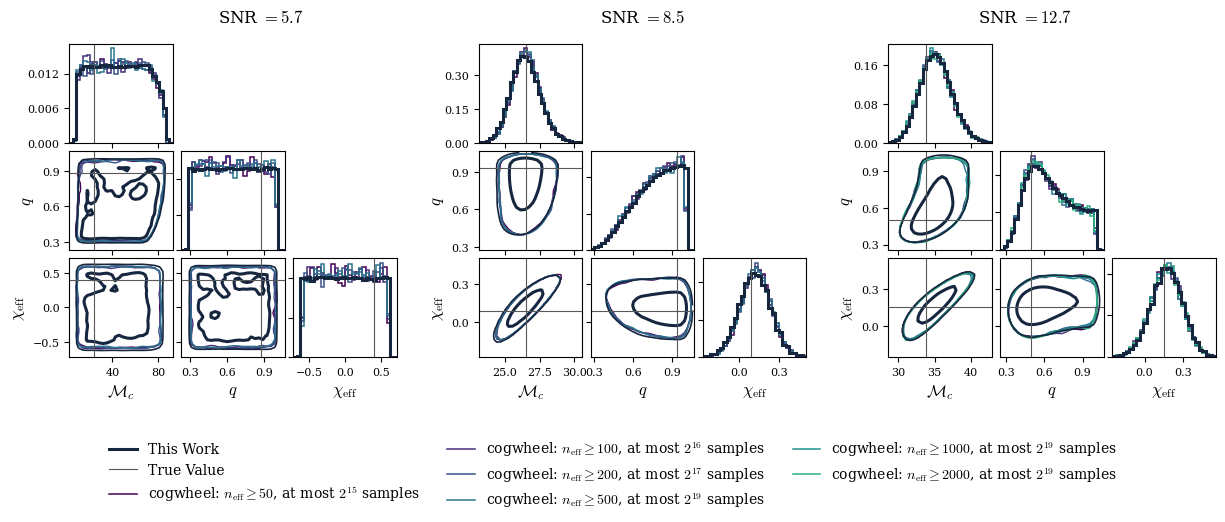

In [5]:
import glob
import figures_validation as figures

bank3 = np.load('../data/banks/three_parameters.npy')
pieces = np.array_split(np.arange(len(bank3)), 10)
store_gpu = search.load_redshift_store('../tables/redshift', pinned=True)
rows_pe = [4, 6, 8]
ln_lambda = np.zeros((len(rows_pe), len(bank3)))
for piece in pieces:
    templates = search.mass_bank(bank3[piece], segments, 'gpu')
    ln_lambda[:, piece] = search.pe_intrinsic(segments, templates, store_gpu, rows=rows_pe, prior='volume', resident=True)['ln_lambda']

def chirp_mass(M, q):
    return M * (q / (1 + q) ** 2) ** 0.6

M, q, chi = bank3[:, 0], bank3[:, 1], bank3[:, 2]
cell = np.ones(len(bank3))
for axis in (M, q, chi):
    values = np.unique(axis)
    cell = cell * np.gradient(values)[np.searchsorted(values, axis)]
truth = np.load(segments)
settings = [(50, 15), (100, 16), (200, 17), (500, 19), (1000, 19), (2000, 19), (10 ** 6, 19), (10 ** 6, 20)]
colors = plt.cm.viridis(np.linspace(0.0, 0.9, 8))         # the colors of the figure above
rng = np.random.default_rng(1)
panels = []
for e, row in enumerate(rows_pe):
    lp = ln_lambda[e] + np.log(cell / cell.sum())
    weights = np.exp(lp - lp.max())
    pick = rng.choice(len(bank3), size=200000, p=weights / weights.sum())
    ours = {}
    for name, axis in (('M', M), ('q', q), ('chi', chi)):
        values = np.unique(axis)
        width = np.gradient(values)[np.searchsorted(values, axis)]
        ours[name] = axis[pick] + (rng.random(pick.size) - 0.5) * width[pick]
    cog = []
    for k, (neff, cap) in enumerate(settings):
        f = '../data/results/cogwheel_pe_row%d_neff%d_cap%d.npz' % (row, neff, cap)
        if not glob.glob(f):
            continue
        c = np.load(f)
        keep = (c['M'] >= 20) & (c['M'] <= 200)
        cog.append(dict(Mc=chirp_mass(c['M'][keep], c['q'][keep]), q=c['q'][keep], chi=c['chi'][keep],
                        weight=c['weights'][keep] * (1 + c['q'][keep]) ** 2 / c['M'][keep], color=colors[k],
                        label=r'cogwheel: $n_{\rm eff} \geq %d$, at most $2^{%d}$ samples' % (neff, cap)))
    panels.append(dict(ours_Mc=chirp_mass(ours['M'], ours['q']), ours_q=ours['q'], ours_chi=ours['chi'], cog=cog,
                       true_Mc=chirp_mass(truth['true_M_det'][row], truth['true_q'][row]), true_q=truth['true_q'][row],
                       true_chi=truth['true_chi'][row], rho=truth['snr'][row]))
figures.fig_corner_cogwheel(panels)